In [1]:
import sys
sys.path.append("..")

import pandas as pd

from clean_data import feature_engineering
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import shap
import numpy as np
import matplotlib.pyplot as plt


c:\Users\tprze\Desktop\ShelterPal\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
df= pd.read_csv("../data/austin/raw/aac_intakes_outcomes.csv")

df = feature_engineering(df)
df_dogs = df[df["animal_type"] == "Dog"]
df_dogs = df_dogs.drop(columns=["young_and_cat","animal_type"])

df_dogs["day_of_week"] = df_dogs["intake_datetime"].dt.day_of_week

X = df_dogs.drop(columns=["time_in_shelter_days", "time_in_shelter","outcome_subtype","outcome_type","sex_upon_outcome","intake_datetime"])
Y = df_dogs["time_in_shelter_days"]
print(Y.isna().sum())

0


In [ ]:
import json
import requests
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

BINS = [-np.inf, 3.0, 14.0, 30.0, np.inf]
LABELS = [
    "do 3 dni",
    "od 4 do 14 dni",
    "od 15 do 30 dni",
    "powyżej 30 dni"
]

# 1. Bierzemy pierwsze 100 psów i resetujemy indeksy, żeby uniknąć NaN i błędów dopasowania
sample_df = df_dogs.head(100).copy().reset_index(drop=True)
sample_y = Y.loc[df_dogs.head(100).index].reset_index(drop=True)

# 2. Tworzymy czysty int jako etykietę celu
sample_df["target_category"] = pd.cut(sample_y, bins=BINS, labels=False).astype(int)

# 3. Funkcja tworząca kontekst
def row_to_state(row):
    plec = "Samiec" if row.get("sex") == "Male" else "Samica"
    kastracja = "wykastrowany/wysterylizowana" if row.get("intact") == "Neutered" else "płodny"
    rasa = "mieszaniec" if row.get("is_mixed_breed") == 1 else "czysta rasa"
    stan = row.get("intake_condition", "Normalny")
    typ = row.get("intake_type", "Nieznany")
    wiek = row.get("age_upon_intake_(years)", "nieznany")
    
    return (
        f"Pies trafił do schroniska w stanie: {stan}. "
        f"Typ przyjęcia: {typ}. Wiek: około {wiek} lat. "
        f"Płeć i stan: {plec}, {kastracja}. Rasa: {rasa}."
    )

QUESTION = "Jak długo zwierzę pozostanie w schronisku?"
URL = "http://localhost:8000/v1/decide"
HEADERS = {"Content-Type": "application/json"}

y_true = []
y_pred = []

print("Wysyłanie próbek do modelu...")

for idx, row in sample_df.iterrows():
    state_desc = row_to_state(row)
    true_label = int(row["target_category"])
    
    payload = {
        "state": state_desc,
        "questions": [
            {
                "question": QUESTION,
                "options": LABELS
            }
        ]
    }
    
    try:
        res = requests.post(URL, json=payload, headers=HEADERS, timeout=10).json()
        probs = res["decisions"][0]["probabilities"]
        predicted_idx = int(np.argmax(probs))
        
        y_true.append(true_label)
        y_pred.append(predicted_idx)
    except Exception as e:
        print(f"Błąd przy rekordzie {idx}: {e}")
        continue

# 5. Wyniki
if y_true:
    print(f"\nPrzetestowano rekordów: {len(y_true)}")
    print(f"Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%\n")
    print(classification_report(y_true, y_pred, target_names=LABELS, zero_division=0))

Wysyłanie próbek do modelu...


ValueError: cannot convert float NaN to integer

In [8]:
X = df_dogs.drop(columns=["time_in_shelter_days", "time_in_shelter","outcome_subtype","outcome_type","sex_upon_outcome","intake_datetime"])
Y = df_dogs["time_in_shelter_days"]
cathegorical_features = ["intake_condition","intake_type","age_upon_intake_age_group","sex","intact","primary_breed_top","age_group"]

train_end = int(len(X) * 0.8)
X_train, X_test = X[:train_end], X[train_end:]
y_train, y_test = Y[:train_end], Y[train_end:]
Y.head()

0    0.588194
1    1.259722
2    1.113889
3    4.970139
4    0.119444
Name: time_in_shelter_days, dtype: float64

In [4]:


model_reg = CatBoostRegressor(
    iterations=600,
    learning_rate=0.03,
    depth=6,
    loss_function='RMSE',
    random_seed=42,
    verbose=100
)

# Trenowanie
model_reg.fit(
    X_train, y_train,
    cat_features=cathegorical_features,
    eval_set=(X_test, y_test),
    early_stopping_rounds=50,
    use_best_model=True
)


0:	learn: 48.5251940	test: 22.7691818	best: 22.7691818 (0)	total: 221ms	remaining: 2m 12s
100:	learn: 47.2293828	test: 21.4200110	best: 21.4200110 (100)	total: 3.97s	remaining: 19.6s
200:	learn: 46.9247458	test: 21.2372983	best: 21.2372983 (200)	total: 7.69s	remaining: 15.3s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 21.22660989
bestIteration = 225

Shrink model to first 226 iterations.


CatBoostRegressor(depth=6, iterations=600, learning_rate=0.03, loss_function='RMSE', random_seed=42, verbose=100)

# MSE


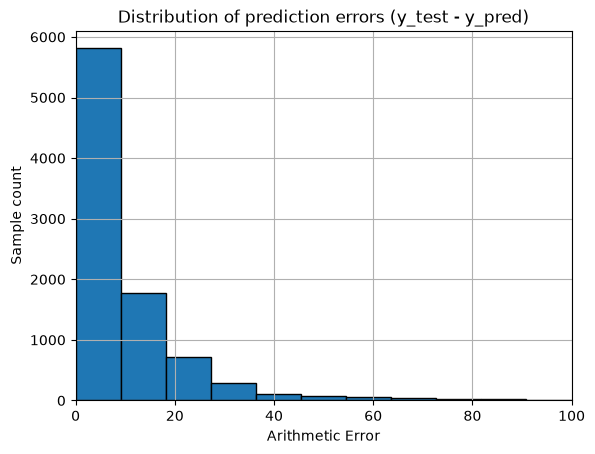

MSE:  450.5690
RMSE: 21.2266 (day unit
MAE:  11.2673
R²:   0.0824


In [5]:

y_pred = model_reg.predict(X_test)

mae_df = pd.DataFrame({"y_test": y_test, "y_pred": y_pred})
mae_df["ArithmeticError"] = np.abs(mae_df["y_test"] - mae_df["y_pred"])

mae_df["ArithmeticError"].hist(bins=40, edgecolor="black")
plt.title("Distribution of prediction errors (y_test - y_pred)")
plt.xlabel("Arithmetic Error")
plt.ylabel("Sample count")
plt.xlim(0,100)
plt.show()

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE:  {mse:.4f}") 
print(f"RMSE: {rmse:.4f} (day unit")
print(f"MAE:  {mae:.4f}")
print(f"R²:   {r2:.4f}")

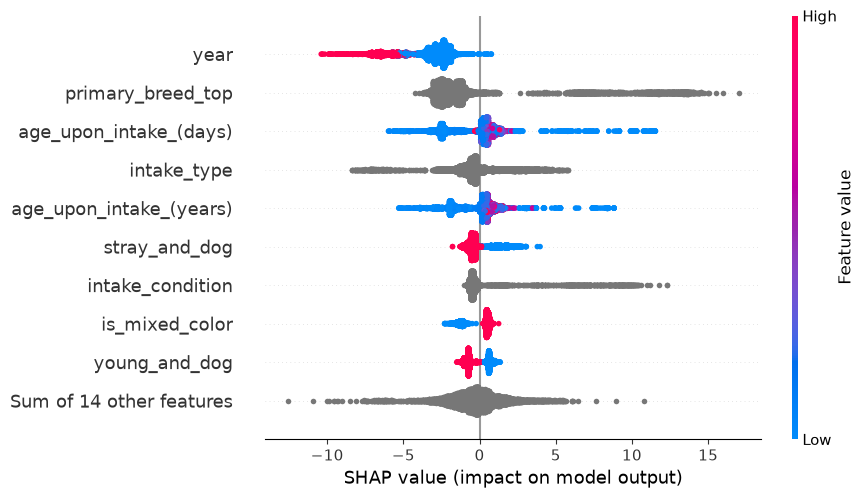

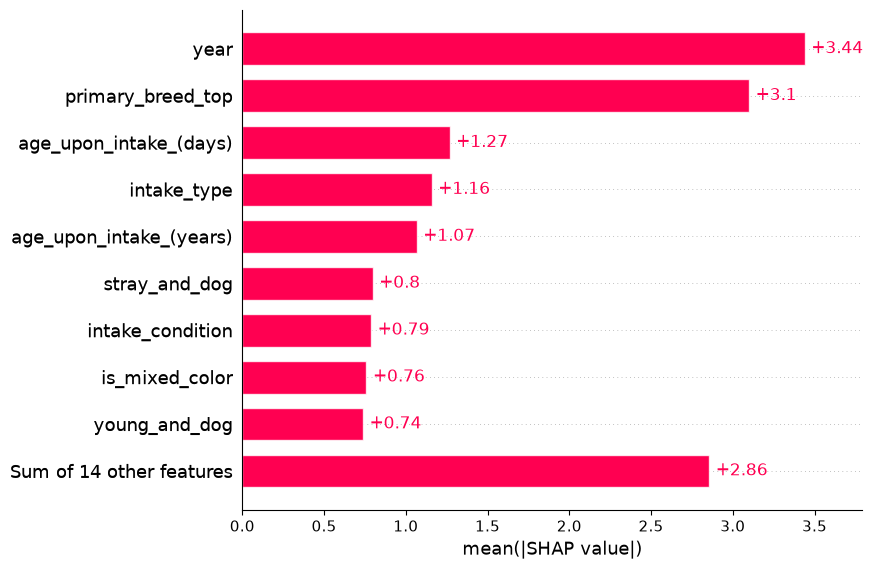

In [6]:



explainer = shap.TreeExplainer(model_reg)


shap_values = explainer(X_test)


shap.plots.beeswarm(shap_values)
shap.plots.bar(shap_values)